# Telco Customer Churn EDA 

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (11, 5)

pd.set_option("display.max_columns", None)

In [ ]:
df = pd.read_excel("data/Telco_customer_churn.xlsx")
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

In [4]:
df.shape

(7043, 33)

In [5]:
df.isna().sum()[df.isna().sum() > 0]

Churn Reason    5174
dtype: int64

In [ ]:
df["Total Charges"] = pd.to_numeric(df["Total Charges"], errors="coerce")
df["Senior Citizen"] = df["Senior Citizen"].map({"Yes": 1, "No": 0})

df.describe().T

,count,mean,std,min,25%,50%,75%,max
Count,7043.0,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000
Zip Code,7043.0,93521.964646,1865.794555,90001.000000,92102.000000,93552.000000,95351.000000,96161.000000
Latitude,7043.0,36.282441,2.455723,32.555828,34.030915,36.391777,38.224869,41.962127
Longitude,7043.0,-119.798880,2.157889,-124.301372,-121.815412,-119.730885,-118.043237,-114.192901
Senior Citizen,7043.0,0.162147,0.368612,0.000000,0.000000,0.000000,0.000000,1.000000
Tenure Months,7043.0,32.371149,24.559481,0.000000,9.000000,29.000000,55.000000,72.000000
Monthly Charges,7043.0,64.761692,30.090047,18.250000,35.500000,70.350000,89.850000,118.750000
Total Charges,7032.0,2283.300441,2266.771362,18.800000,401.450000,1397.475000,3794.737500,8684.800000
Churn Value,7043.0,0.265370,0.441561,0.000000,0.000000,0.000000,1.000000,1.000000
Churn Score,7043.0,58.699418,21.525131,5.000000,40.000000,61.000000,75.000000,100.000000


## Churn

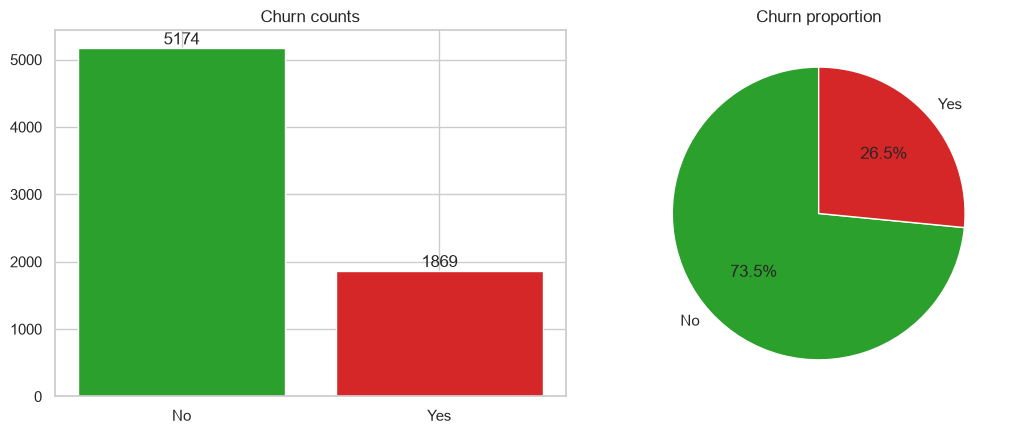

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

counts = df["Churn Value"].value_counts().sort_index()
ax[0].bar(["No", "Yes"], counts.values, color=["#2ca02c", "#d62728"])
ax[0].set_title("Churn counts")
for i, v in enumerate(counts.values):
    ax[0].text(i, v, str(v), ha="center", va="bottom")

df["Churn Value"].value_counts(normalize=True).sort_index().plot.pie(
    ax=ax[1],
    labels=["No", "Yes"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#2ca02c", "#d62728"],
)
ax[1].set_ylabel("")
ax[1].set_title("Churn proportion")
plt.tight_layout()
plt.show()

## Univariate Analysis

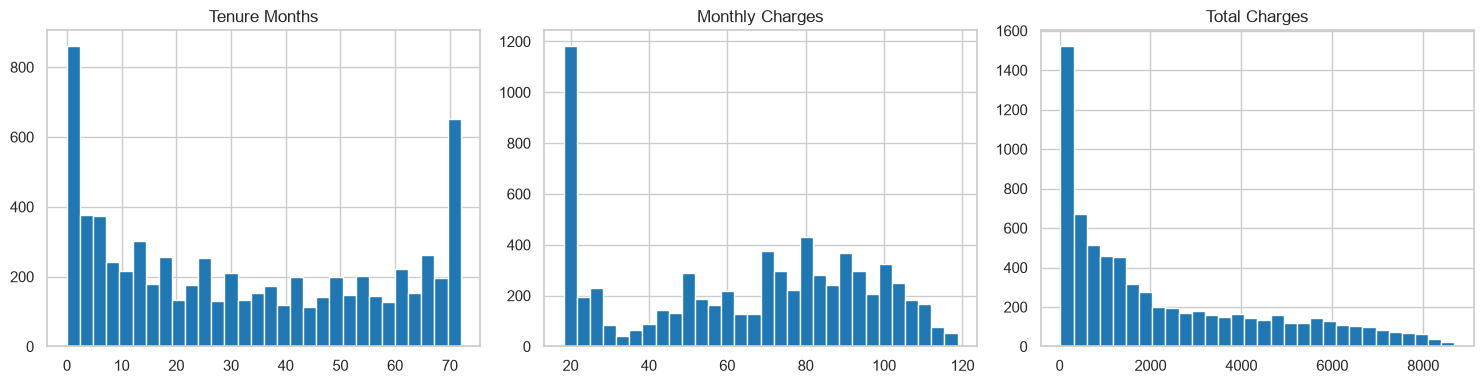

In [8]:
num_cols = ["Tenure Months", "Monthly Charges", "Total Charges"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    df[col].hist(ax=ax, bins=30, color="#1f77b4")
    ax.set_title(col)
plt.tight_layout()
plt.show()

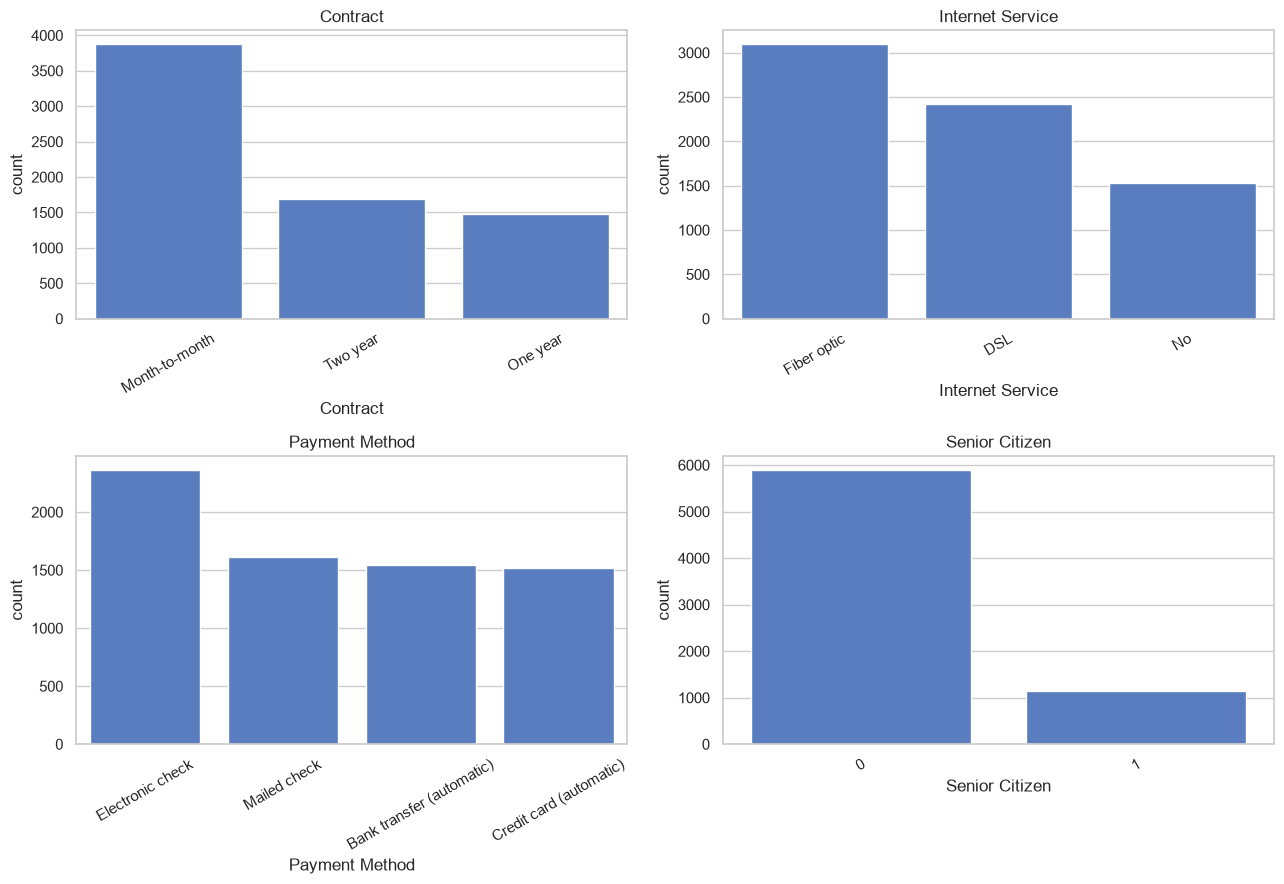

In [9]:
cat_cols = ["Contract", "Internet Service", "Payment Method", "Senior Citizen"]
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.ravel(), cat_cols):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, ax=ax, order=order)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

## Churn vs. Key Features

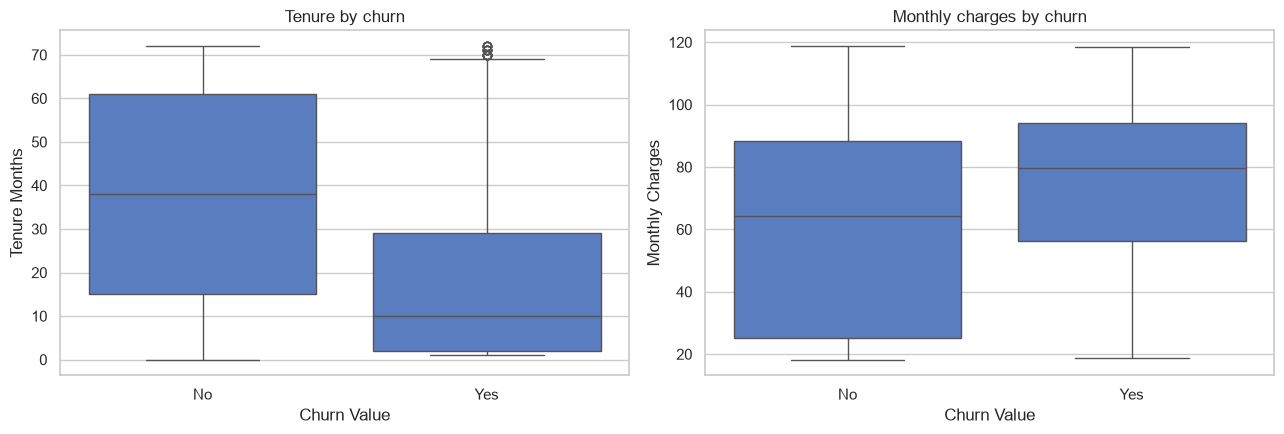

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.boxplot(data=df, x="Churn Value", y="Tenure Months", ax=axes[0])
axes[0].set_xticklabels(["No", "Yes"])
axes[0].set_title("Tenure by churn")

sns.boxplot(data=df, x="Churn Value", y="Monthly Charges", ax=axes[1])
axes[1].set_xticklabels(["No", "Yes"])
axes[1].set_title("Monthly charges by churn")
plt.tight_layout()
plt.show()

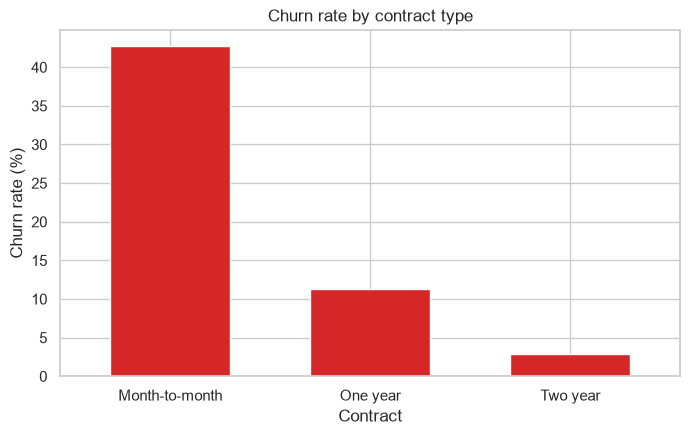

In [11]:
churn_rate = df.groupby("Contract")["Churn Value"].mean().sort_values(ascending=False) * 100
fig, ax = plt.subplots(figsize=(8, 4.5))
churn_rate.plot.bar(ax=ax, color="#d62728", width=0.6)
ax.set_ylabel("Churn rate (%)")
ax.set_title("Churn rate by contract type")
ax.tick_params(axis="x", rotation=0)
plt.show()

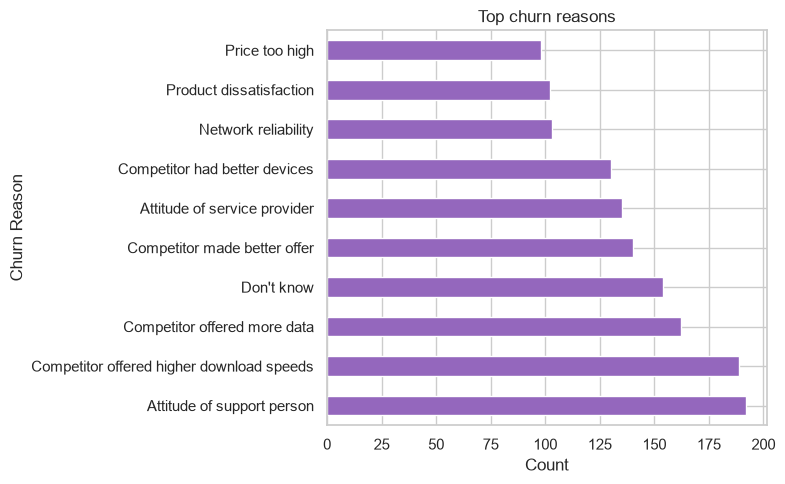

In [12]:
# Top churn reasons (churned customers only)
reasons = df.loc[df["Churn Value"] == 1, "Churn Reason"].value_counts()
fig, ax = plt.subplots(figsize=(8, 5))
reasons.head(10).plot.barh(ax=ax, color="#9467bd")
ax.set_title("Top churn reasons")
ax.set_xlabel("Count")
plt.tight_layout()
plt.show()

## Correlations

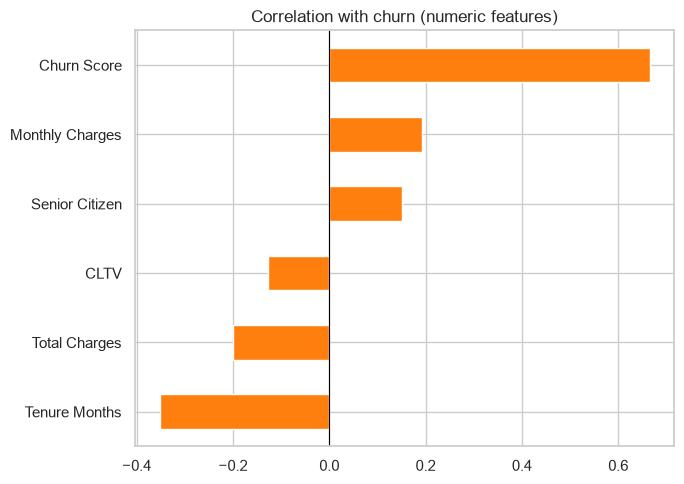

In [13]:
# Correlation of numeric columns with the churn target
numeric = df.select_dtypes(include=[np.number]).drop(columns=["Count", "Zip Code", "Latitude", "Longitude"])
corr = numeric.corr()["Churn Value"].drop("Churn Value").sort_values()

fig, ax = plt.subplots(figsize=(7, 5))
corr.plot.barh(ax=ax, color="#ff7f0e")
ax.set_title("Correlation with churn (numeric features)")
ax.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()